### Setup

In [2]:
from pathlib import Path
from collections import Counter
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_project_root():
    current = Path.cwd().resolve()

    for candidate in [current, *current.parents]:
        if (
            (candidate / "main.py").exists()
            and (candidate / "thesis").exists()
            and (candidate / "splits").exists()
        ):
            return candidate

    raise RuntimeError(
        "PyCIL project root not found."
    )


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT)
    )


from thesis.data.samplers import (
    compute_inverse_frequency_weights,
    build_weighted_sampler,
)


AID_SPLIT_ROOT = (
    PROJECT_ROOT
    / "splits"
    / "aid"
    / "seed_1993"
)

NWPU_SPLIT_ROOT = (
    PROJECT_ROOT
    / "splits"
    / "nwpu"
    / "seed_1993"
)

print("Project root:", PROJECT_ROOT)

Project root: C:\Skripsi\Project\PyCIL


### Load manifest and task config

In [3]:
aid_train = pd.read_csv(
    AID_SPLIT_ROOT / "train.csv"
)

aid_test = pd.read_csv(
    AID_SPLIT_ROOT / "test.csv"
)

nwpu_train = pd.read_csv(
    NWPU_SPLIT_ROOT / "train.csv"
)

nwpu_test = pd.read_csv(
    NWPU_SPLIT_ROOT / "test.csv"
)


with open(
    AID_SPLIT_ROOT / "T5_tasks.json",
    encoding="utf-8"
) as f:
    aid_T5 = json.load(f)


with open(
    AID_SPLIT_ROOT / "T10_tasks.json",
    encoding="utf-8"
) as f:
    aid_T10 = json.load(f)


with open(
    NWPU_SPLIT_ROOT / "T5_tasks.json",
    encoding="utf-8"
) as f:
    nwpu_T5 = json.load(f)


with open(
    NWPU_SPLIT_ROOT / "T10_tasks.json",
    encoding="utf-8"
) as f:
    nwpu_T10 = json.load(f)


print(
    "AID:",
    len(aid_train),
    "train /",
    len(aid_test),
    "test"
)

print(
    "NWPU:",
    len(nwpu_train),
    "train /",
    len(nwpu_test),
    "test"
)

AID: 8000 train / 2000 test
NWPU: 25200 train / 6300 test


### Get data on certain incremental task

In [4]:
def get_task_dataframe(
    dataframe,
    task_config,
    task_id
):
    class_ids = (
        task_config["tasks"][task_id]
        ["original_class_ids"]
    )

    task_df = dataframe[
        dataframe[
            "original_class_id"
        ].isin(class_ids)
    ].copy()

    return (
        task_df
        .reset_index(drop=True)
    )

In [5]:
aid_T5_task0 = get_task_dataframe(
    aid_train,
    aid_T5,
    task_id=0
)

print(
    "Task 0 images:",
    len(aid_T5_task0)
)

print(
    "Task 0 classes:",
    aid_T5_task0[
        "original_class_id"
    ].nunique()
)

Task 0 images: 3656
Task 0 classes: 14


### Imbalance on AID dataset

In [6]:
raw_counts = (
    aid_T5_task0
    ["original_class_id"]
    .value_counts()
    .sort_index()
)

display(raw_counts)

print(
    "Minimum:",
    raw_counts.min()
)

print(
    "Maximum:",
    raw_counts.max()
)

original_class_id
2     176
6     192
8     328
10    296
12    312
13    224
14    232
15    272
20    304
21    208
23    328
26    264
27    232
28    288
Name: count, dtype: int64

Minimum: 176
Maximum: 328


### Weights Verification

In [7]:
labels = (
    aid_T5_task0[
        "original_class_id"
    ]
    .to_numpy()
)

weights = (
    compute_inverse_frequency_weights(
        labels
    )
)

aid_T5_task0[
    "sampling_weight"
] = weights.numpy()

class_total_weights = (
    aid_T5_task0
    .groupby(
        "original_class_id"
    )["sampling_weight"]
    .sum()
)

display(class_total_weights)

original_class_id
2     1.0
6     1.0
8     1.0
10    1.0
12    1.0
13    1.0
14    1.0
15    1.0
20    1.0
21    1.0
23    1.0
26    1.0
27    1.0
28    1.0
Name: sampling_weight, dtype: float64

### Sample one epoch

In [8]:
sampler = build_weighted_sampler(
    labels,
    seed=1993,
    num_samples=len(labels),
    replacement=True,
)

sampled_indices = np.array(
    list(iter(sampler))
)

sampled_labels = labels[
    sampled_indices
]

sampled_counts = pd.Series(
    sampled_labels
).value_counts().sort_index()

comparison = pd.DataFrame({
    "original_train_count":
        raw_counts,

    "sampled_count_one_epoch":
        sampled_counts,
})

display(comparison)

,original_train_count,sampled_count_one_epoch
2,176,243
6,192,261
8,328,271
10,296,240
12,312,254
13,224,279
14,232,259
15,272,237
20,304,285
21,208,270


### Original vs Sampled

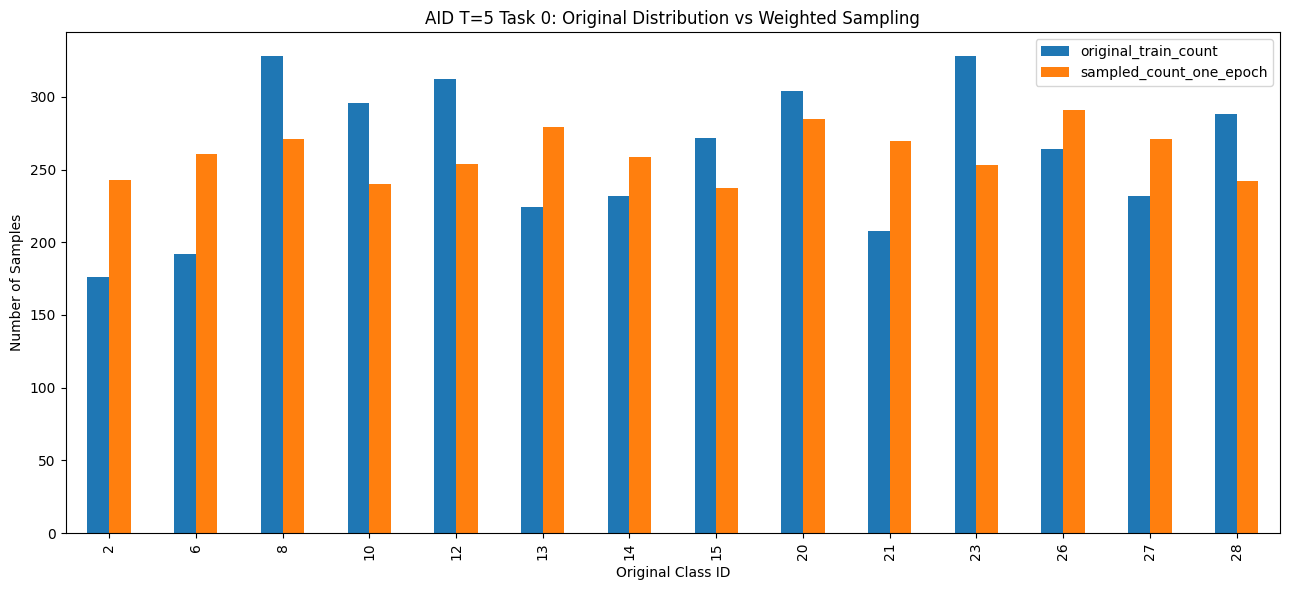

In [9]:
comparison.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title(
    "AID T=5 Task 0: "
    "Original Distribution vs Weighted Sampling"
)

plt.xlabel(
    "Original Class ID"
)

plt.ylabel(
    "Number of Samples"
)

plt.tight_layout()
plt.show()

### Simulate many epochs


In [10]:
def simulate_sampler(
    labels,
    epochs=50,
    base_seed=1993
):
    labels = np.asarray(labels)

    sampled_all = []

    for epoch in range(epochs):

        sampler = build_weighted_sampler(
            labels,
            seed=base_seed + epoch,
            num_samples=len(labels),
            replacement=True,
        )

        indices = np.array(
            list(iter(sampler))
        )

        sampled_all.append(
            labels[indices]
        )

    return np.concatenate(
        sampled_all
    )

In [12]:
sampled_50_epochs = simulate_sampler(
    labels,
    epochs=50,
    base_seed=1993
)

empirical_probability = (
    pd.Series(sampled_50_epochs)
    .value_counts(normalize=True)
    .sort_index()
)

expected_probability = (
    1.0
    / len(np.unique(labels))
)

print(
    "Expected probability per class:",
    expected_probability
)

display(empirical_probability)

Expected probability per class: 0.07142857142857142


2     0.071100
6     0.071242
8     0.072205
10    0.070952
12    0.071997
13    0.071559
14    0.070607
15    0.071712
20    0.070853
21    0.072292
23    0.071537
26    0.071532
27    0.071165
28    0.071247
Name: proportion, dtype: float64

### Measure deviation from uniform

In [13]:
deviation = (
    empirical_probability
    - expected_probability
).abs()

print(
    "Maximum absolute deviation:",
    deviation.max()
)

assert deviation.max() < 0.02

print(
    "Empirical weighted sampling: PASSED"
)

Maximum absolute deviation: 0.0008635511097217913
Empirical weighted sampling: PASSED


### Deterministic test

In [14]:
sampler_a = build_weighted_sampler(
    labels,
    seed=1993
)

sampler_b = build_weighted_sampler(
    labels,
    seed=1993
)

indices_a = list(
    iter(sampler_a)
)

indices_b = list(
    iter(sampler_b)
)

assert indices_a == indices_b

print(
    "Same seed -> same sampling sequence: PASSED"
)

Same seed -> same sampling sequence: PASSED


In [15]:
sampler_c = build_weighted_sampler(
    labels,
    seed=1994
)

indices_c = list(
    iter(sampler_c)
)

assert indices_a != indices_c

print(
    "Different seed -> different sampling sequence: PASSED"
)

Different seed -> different sampling sequence: PASSED


### Validate all task AID T=5

In [16]:
def validate_all_aid_tasks(
    train_df,
    task_config
):
    rows = []

    for task in task_config["tasks"]:

        task_id = task["task_id"]

        task_df = get_task_dataframe(
            train_df,
            task_config,
            task_id
        )

        labels = task_df[
            "original_class_id"
        ].to_numpy()

        counts = (
            pd.Series(labels)
            .value_counts()
        )

        sampled = simulate_sampler(
            labels,
            epochs=20,
            base_seed=1993
        )

        probs = (
            pd.Series(sampled)
            .value_counts(
                normalize=True
            )
        )

        expected = (
            1.0
            / len(counts)
        )

        rows.append({
            "task_id":
                task_id,

            "num_classes":
                len(counts),

            "num_samples":
                len(labels),

            "raw_min":
                counts.min(),

            "raw_max":
                counts.max(),

            "expected_probability":
                expected,

            "max_sampling_deviation":
                (
                    probs - expected
                ).abs().max(),
        })

    return pd.DataFrame(rows)

In [17]:
aid_T5_sampler_summary = (
    validate_all_aid_tasks(
        aid_train,
        aid_T5
    )
)

display(
    aid_T5_sampler_summary
)

,task_id,num_classes,num_samples,raw_min,raw_max,expected_probability,max_sampling_deviation
0,0,14,3656,176,328,0.071429,0.001612
1,1,4,928,200,288,0.250000,0.001886
2,2,4,1160,240,336,0.250000,0.001422
3,3,4,1120,240,320,0.250000,0.001473
4,4,4,1136,240,336,0.250000,0.001452


### AID T=10

In [18]:
aid_T10_sampler_summary = (
    validate_all_aid_tasks(
        aid_train,
        aid_T10
    )
)

display(
    aid_T10_sampler_summary
)

,task_id,num_classes,num_samples,raw_min,raw_max,expected_probability,max_sampling_deviation
0,0,12,3056,176,328,0.083333,0.002231
1,1,2,600,288,312,0.500000,0.001750
2,2,2,408,200,208,0.500000,0.003186
3,3,2,520,232,288,0.500000,0.002115
4,4,2,584,288,296,0.500000,0.001712
5,5,2,576,240,336,0.500000,0.001476
6,6,2,520,240,280,0.500000,0.002115
7,7,2,600,280,320,0.500000,0.001750
8,8,2,648,312,336,0.500000,0.003009
9,9,2,488,240,248,0.500000,0.002357


### NWPU as control case

In [19]:
nwpu_task0 = get_task_dataframe(
    nwpu_train,
    nwpu_T5,
    task_id=0
)

nwpu_counts = (
    nwpu_task0[
        "original_class_id"
    ]
    .value_counts()
)

display(nwpu_counts)

original_class_id
0     560
20    560
41    560
38    560
37    560
35    560
30    560
27    560
25    560
24    560
22    560
21    560
19    560
1     560
18    560
17    560
16    560
15    560
13    560
12    560
10    560
8     560
6     560
2     560
43    560
Name: count, dtype: int64

In [20]:
assert nwpu_counts.nunique() == 1
assert nwpu_counts.iloc[0] == 560

print(
    "NWPU is balanced; "
    "WeightedRandomSampler is unnecessary."
)

NWPU is balanced; WeightedRandomSampler is unnecessary.
